In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("./data/Fortnite_Statistics.csv")
#data.info()

<class 'pandas.DataFrame'>
RangeIndex: 87 entries, 0 to 86
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  87 non-null     str    
 1   Time of Day           87 non-null     str    
 2   Placed                87 non-null     int64  
 3   Mental State          87 non-null     str    
 4   Eliminations          87 non-null     int64  
 5   Assists               87 non-null     int64  
 6   Revives               87 non-null     int64  
 7   Accuracy              87 non-null     str    
 8   Hits                  87 non-null     int64  
 9   Head Shots            87 non-null     int64  
 10  Distance Traveled     87 non-null     float64
 11  Materials Gathered    87 non-null     int64  
 12  Materials Used        87 non-null     int64  
 13  Damage Taken          87 non-null     int64  
 14  Damage to Players     87 non-null     int64  
 15  Damage to Structures  87 non-null   

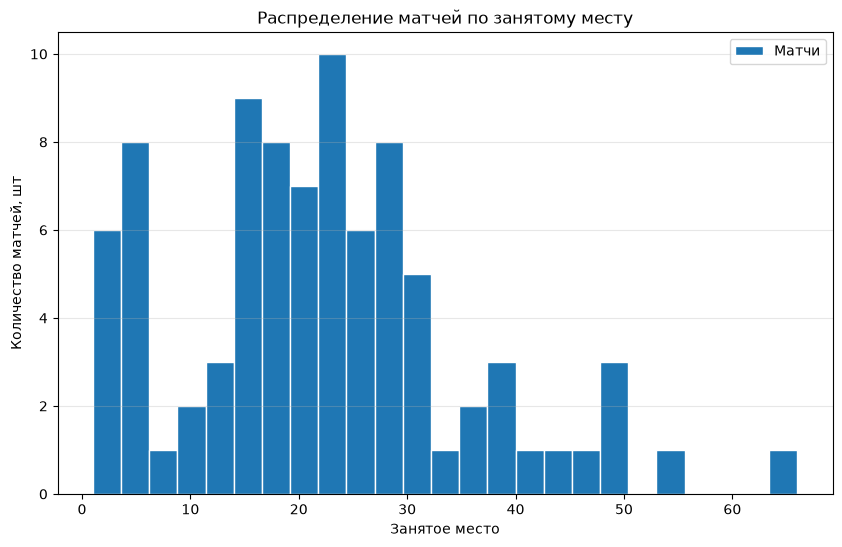

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(data['Placed'], bins=25, edgecolor='white', label='Матчи')
ax.legend()
ax.set_title("Распределение матчей по занятому месту")
ax.set_xlabel("Занятое место")
ax.set_ylabel("Количество матчей, шт")
ax.grid(True, alpha=0.3, axis='y');

Что визуализировали: Распределение 87 матчей по занятому месту.

Выводы: Распределение скошено вправо: основная масса матчей заканчивается
в районе 15-30 места, медиана равна 21. Половина всех матчей укладывается
в диапазон с 15 по 28 место - игрок стабильно доживает до середины партии,
но редко доходит до финала.

Побед всего 3 из 87 (3.4%), в топ-10 игрок попал 16 раз (18%). Левый край
распределения заметно тоньше правого: хороший результат - редкое событие,
тогда как хвост до 66 места показывает, что ранние вылеты случаются регулярно.

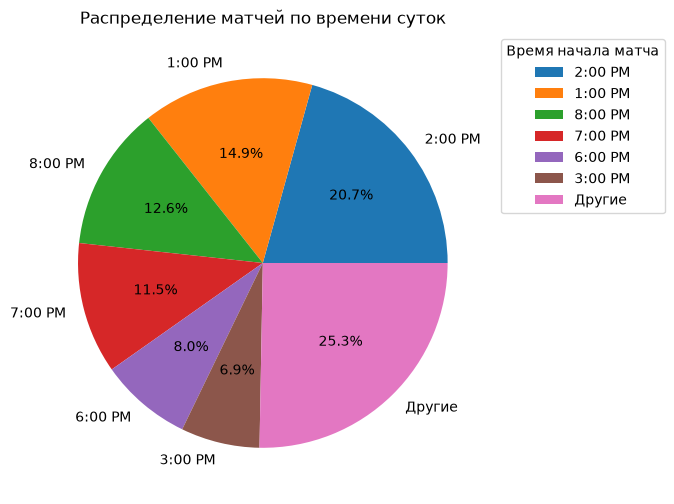

In [10]:
threshold = 5
counts = data['Time of Day'].value_counts()
major = counts[counts > threshold].copy()
major['Другие'] = counts[counts <= threshold].sum()

fig, ax = plt.subplots(figsize=(10, 6))
ax.pie(major.values, labels=major.index, autopct='%.1f%%')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), title='Время начала матча')
ax.set_title("Распределение матчей по времени суток");

Что визуализировали: Доли матчей по часу начала. Часы, на которые пришлось
5 матчей и меньше, объединены в сегмент "Другие" - иначе диаграмма распалась бы
на 13 секторов, часть из которых была бы неразличимо тонкой.

Выводы: Игрок заметно предпочитает два окна: ранний день (13:00–14:00,
вместе 31 матч из 87) и вечер (19:00–20:00, 21 матч). Пик приходится на 14:00 -
18 матчей, или 20.7% всех сессий.

Сегмент "Другие" занимает четверть диаграммы (22 матча), то есть оставшиеся
семь часов в сумме дают немало, но каждый по отдельности случаен. Ночных матчей
почти нет. Расписание выглядит как игра в свободное время между делами,
а не как равномерная активность в течение суток.

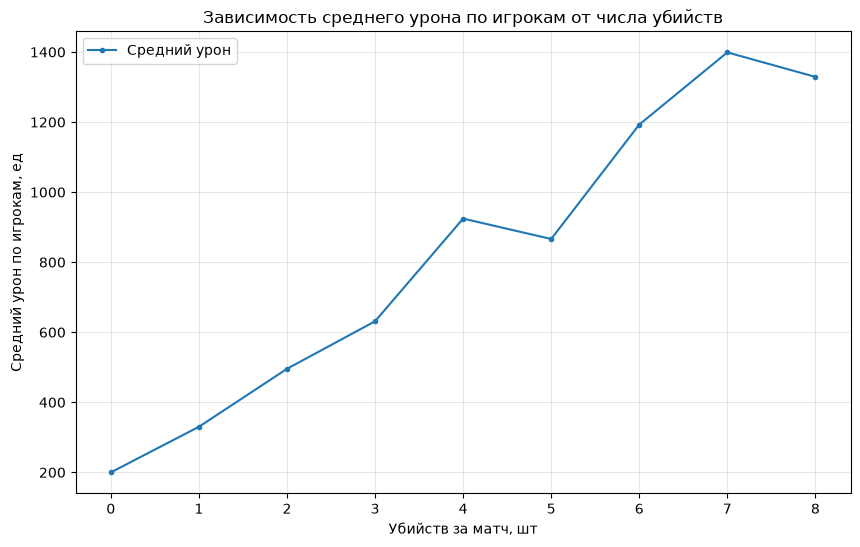

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
series = data.groupby('Eliminations')['Damage to Players'].mean()
ax.plot(series.index, series.values, label='Средний урон', marker='.')
ax.legend()
ax.set_title("Зависимость среднего урона по игрокам от числа убийств")
ax.set_xlabel("Убийств за матч, шт")
ax.set_ylabel("Средний урон по игрокам, ед")
ax.grid(True, alpha=0.3);

Что визуализировали: Средний урон по игрокам для каждого числа убийств
за матч.

Выводы: Зависимость растущая и близка к линейной на участке 0-4 убийства:
от 200 единиц урона при нуле убийств до 924 при четырёх, то есть примерно
180–230 единиц урона на каждое дополнительное убийство. Это согласуется
с механикой игры: полное здоровье противника со щитом - 200 единиц, и часть
нанесённого урона всегда уходит в цели, которых добивает кто-то другой.

Ненулевой урон при нуле убийств (200 единиц в среднем) показывает, что
значительная доля перестрелок не доводится до конца.

Правая часть графика ненадёжна: на 5 убийств приходится 4 матча, на 7 - всего
один, на 8 - два.